# Random Forest Classification

**Name:** Adam Dowling  
**Student ID:** C00298483  
**Module:** Data Science and Machine Learning
**Lecturer:** Ben O'Shaughnessy
**Date:** 8th November 2026

## Purpose

The purpose of this notebook is to investigate whether machine learning can predict Eurovision Song Contest semi-final qualification.

Using a Random Forest Classifier, the model will analyse song characteristics such as energy, danceability, happiness, BPM and semi-final draw position.

Decision Trees use Entropy and Information Gain to determine the best splits when classifying data. The notebook will investigate how these techniques can
be applied to Eurovision results.


In [1]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [2]:
songs = pd.read_csv(
    "archive/Kaggle Dataset/song_data.csv",
    encoding="latin-1"
)

songs.head()

,year,semi_final,semi_draw_position,final_draw_position,country,artist_name,song_name,language,style,direct_qualifier_10,...,final_jury_votes,final_place,final_total_points,semi_place,semi_televote_points,semi_jury_points,semi_total_points,favourite_10,race,host_10
0,2023,1,1,20,Norway,Alessandra,Queen of Kings,English,Pop,0,...,11.0,5.0,268.0,6.0,102.0,NaN,102.0,0,unknown,0
1,2023,1,2,NaN,Malta,The Busker,Dance (Our Own Party),English,Pop,-,...,NaN,NaN,NaN,15.0,3.0,NaN,3.0,0,unknown,0
2,2023,1,3,5,Serbia,Luke Black,Samo mi se spava,"Serbian, English",Pop,0,...,6.0,24.0,30.0,10.0,37.0,NaN,37.0,0,unknown,0
3,2023,1,4,NaN,Latvia,Sudden Lights,Aija,English,Rock,-,...,NaN,NaN,NaN,11.0,34.0,NaN,34.0,0,unknown,0
4,2023,1,5,2,Portugal,Mimicat,Ai coração,Portuguese,Pop,0,...,9.0,23.0,59.0,9.0,74.0,NaN,74.0,0,unknown,0


In [3]:
print("Dataset dimensions:", songs.shape)
print("Number of songs:", songs.shape[0])
print("Number of columns:", songs.shape[1])

Dataset dimensions: (565, 44)
Number of songs: 565
Number of columns: 44


In [4]:
songs.columns.tolist()

['year',
 'semi_final',
 'semi_draw_position',
 'final_draw_position',
 'country',
 'artist_name',
 'song_name',
 'language',
 'style',
 'direct_qualifier_10',
 'gender',
 'main_singers',
 'age',
 'selection',
 'key',
 'BPM',
 'energy',
 'danceability',
 'happiness',
 'loudness',
 'acousticness',
 'instrumentalness',
 'liveness',
 'speechiness',
 'release_date',
 'key_change_10',
 'backing_dancers',
 'backing_singers',
 'backing_instruments',
 'instrument_10',
 'qualified_10',
 'final_televote_points',
 'final_jury_points',
 'final_televote_votes',
 'final_jury_votes',
 'final_place',
 'final_total_points',
 'semi_place',
 'semi_televote_points',
 'semi_jury_points',
 'semi_total_points',
 'favourite_10',
 'race',
 'host_10']

In [5]:
songs[['country', 'song_name', 'semi_draw_position',
       'energy', 'danceability', 'happiness',
       'BPM', 'qualified_10']].head(10)

,country,song_name,semi_draw_position,energy,danceability,happiness,BPM,qualified_10
0,Norway,Queen of Kings,1,36,64,23,110,1
1,Malta,Dance (Our Own Party),2,78,70,82,103,0
2,Serbia,Samo mi se spava,3,70,56,11,103,1
3,Latvia,Aija,4,55,56,40,160,0
4,Portugal,Ai coração,5,63,66,77,145,1
5,Ireland,We Are One,6,66,47,12,112,0
6,Croatia,Mama C!,7,78,60,63,135,0
7,Switzerland,Watergun,8,87,68,39,130,1
8,Israel,Unicorn,9,87,68,28,130,1
9,Moldova,Soarele si luna,10,86,62,34,125,1


## Data Selection and Preprocessing

The Eurovision dataset contains several different
attributes for each song.
For this experiment, five features have been selected:
- Semi-final draw position
- Energy
- Danceability
- Happiness
- Beats per minute (BPM)
  
The target variable is qualified_10, which indicates
whether a song qualified for the Eurovision final.
These features will be used to train the random forest.

In [6]:
features = [
    'semi_draw_position',
    'energy',
    'danceability',
    'happiness',
    'BPM'
]

target = 'qualified_10'
X = songs[features].copy()
y = songs[target].copy()

print("Selected features:")
print(X.head())
print("\nTarget variable:")
print(y.head())

Selected features:
  semi_draw_position energy danceability happiness  BPM
0                  1     36           64        23  110
1                  2     78           70        82  103
2                  3     70           56        11  103
3                  4     55           56        40  160
4                  5     63           66        77  145

Target variable:
0    1
1    0
2    1
3    0
4    1
Name: qualified_10, dtype: str


In [7]:
X = X.replace('unknown', np.nan)

for column in features:
    X[column] = pd.to_numeric(
        X[column],
        errors='coerce'
    )

y = pd.to_numeric(y, errors='coerce')
# Remove entries without a known qualification result
valid_rows = y.notna()
X = X.loc[valid_rows]
y = y.loc[valid_rows].astype(int)

print("Remaining entries:", len(X))
print("\nMissing feature values:")
print(X.isnull().sum())
print("\nQualification results:")
print(y.value_counts())

Remaining entries: 485

Missing feature values:
semi_draw_position     0
energy                80
danceability          80
happiness             80
BPM                   80
dtype: int64

Qualification results:
qualified_10
1    279
0    206
Name: count, dtype: int64


## Qualification Distribution ##
After removing entries without a known qualification result, 485 Eurovision entries remain. 279 qualified and 206 did not qualify. 
The distribution is not perfectly balanced, so accuracy should be interpreted alongside the proportion of songs in each class. The audio features contain missing values; these are handled using median imputation within the training pipeline.

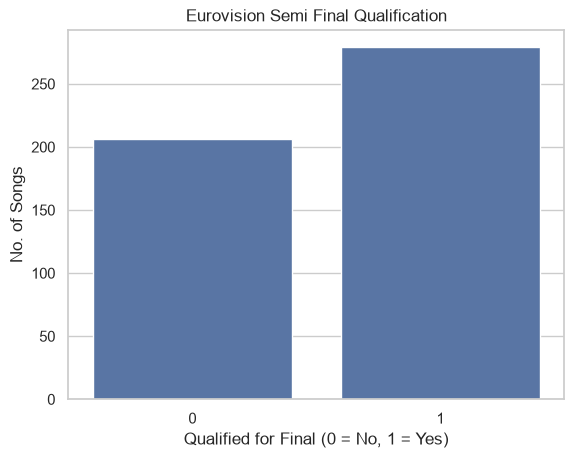

In [8]:
sns.countplot(x=y)

plt.title('Eurovision Semi Final Qualification')
plt.xlabel('Qualified for Final (0 = No, 1 = Yes)')
plt.ylabel('No. of Songs')

plt.show()

## Decision Trees

A decision tree is a supervised machine learning algorithm that can be used for classification and regression tasks.
It works by splitting a dataset into smaller groups based on the values of selected features.

For this experiment, a decision tree will investigate whether song characteristics such as energy, danceability, happiness, BPM, and semi final draw position can help predict whether a song qualifies for the final.

The algorithm uses entropy and information gain to determine which feature and split provide the best separation between the qualification classes.

In [9]:
class_probabilities = y.value_counts(normalize=True) #calculating proportion of each qual class
entropy = -np.sum(
    class_probabilities * np.log2(class_probabilities)
)

print("Qualification distribution:")
print(y.value_counts())
print("\nClass probabilities:")
print(class_probabilities)
print("\nDataset Entropy:", round(entropy, 4))

Qualification distribution:
qualified_10
1    279
0    206
Name: count, dtype: int64

Class probabilities:
qualified_10
1    0.575258
0    0.424742
Name: proportion, dtype: float64

Dataset Entropy: 0.9836


## Information Gain

Information Gain measures how much uncertainty is reduced when a dataset is split into smaller groups.

It is calculated by subtracting the weighted entropy of the child groups from the original dataset entropy.
Information Gain = Parent Entropy - Weighted Child Entropy

The decision tree evaluates possible splits and favours those that produce the greatest reduction in entropy.
For example, it may investigate whether splitting Eurovision entries based on their BPM creates groups with clearer qualification outcomes.


In [10]:
def calculate_entropy(target_values):
    probabilities = target_values.value_counts(normalize=True)
    return -np.sum(
        probabilities * np.log2(probabilities)
    )
bpm_values = X['BPM'].fillna(X['BPM'].median()) #missing values filled with median bpm
median_bpm = bpm_values.median() #median bpm
low_bpm = y[bpm_values <= median_bpm] #split songs into low and high bpm
high_bpm = y[bpm_values > median_bpm]
parent_entropy = calculate_entropy(y)
low_entropy = calculate_entropy(low_bpm)
high_entropy = calculate_entropy(high_bpm)

weighted_entropy = (
    (len(low_bpm) / len(y)) * low_entropy + (len(high_bpm) / len(y)) * high_entropy
)
information_gain = parent_entropy - weighted_entropy

print("Median BPM:", median_bpm)
print("Parent Entropy:", round(parent_entropy, 4))
print("Low BPM Entropy:", round(low_entropy, 4))
print("High BPM Entropy:", round(high_entropy, 4))
print("Information Gain:", round(information_gain, 4))

Median BPM: 120.0
Parent Entropy: 0.9836
Low BPM Entropy: 0.9864
High BPM Entropy: 0.9788
Information Gain: 0.0002


## Training and testing the Decision Tree 

The dataset is divided into 363 training entries and 122 testing entries. The training entries are used to learn the decision rules, while the test entries are used to assess predictions on unseen songs. Median imputation handles missing audio features, with the median values learned from the training set. 

The decision tree uses entropy as its splitting criterion, connecting the implementation to the earlier entropy and information gain calculations.

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score

Xtrain, Xtest, ytrain, ytest = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42,
    stratify=y
)

print("Training entries:", len(Xtrain))
print("Testing entries:", len(Xtest))

Training entries: 363
Testing entries: 122


In [12]:
tree_model = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('tree', DecisionTreeClassifier(
        criterion='entropy',
        random_state=42
    ))
])

tree_model.fit(Xtrain, ytrain) #train decision tree
tree_predictions = tree_model.predict(Xtest) #predict qualifiers

print("Training finished")
print("Overall accuracy is",
      accuracy_score(ytest, tree_predictions))

Training finished
Overall accuracy is 0.5655737704918032


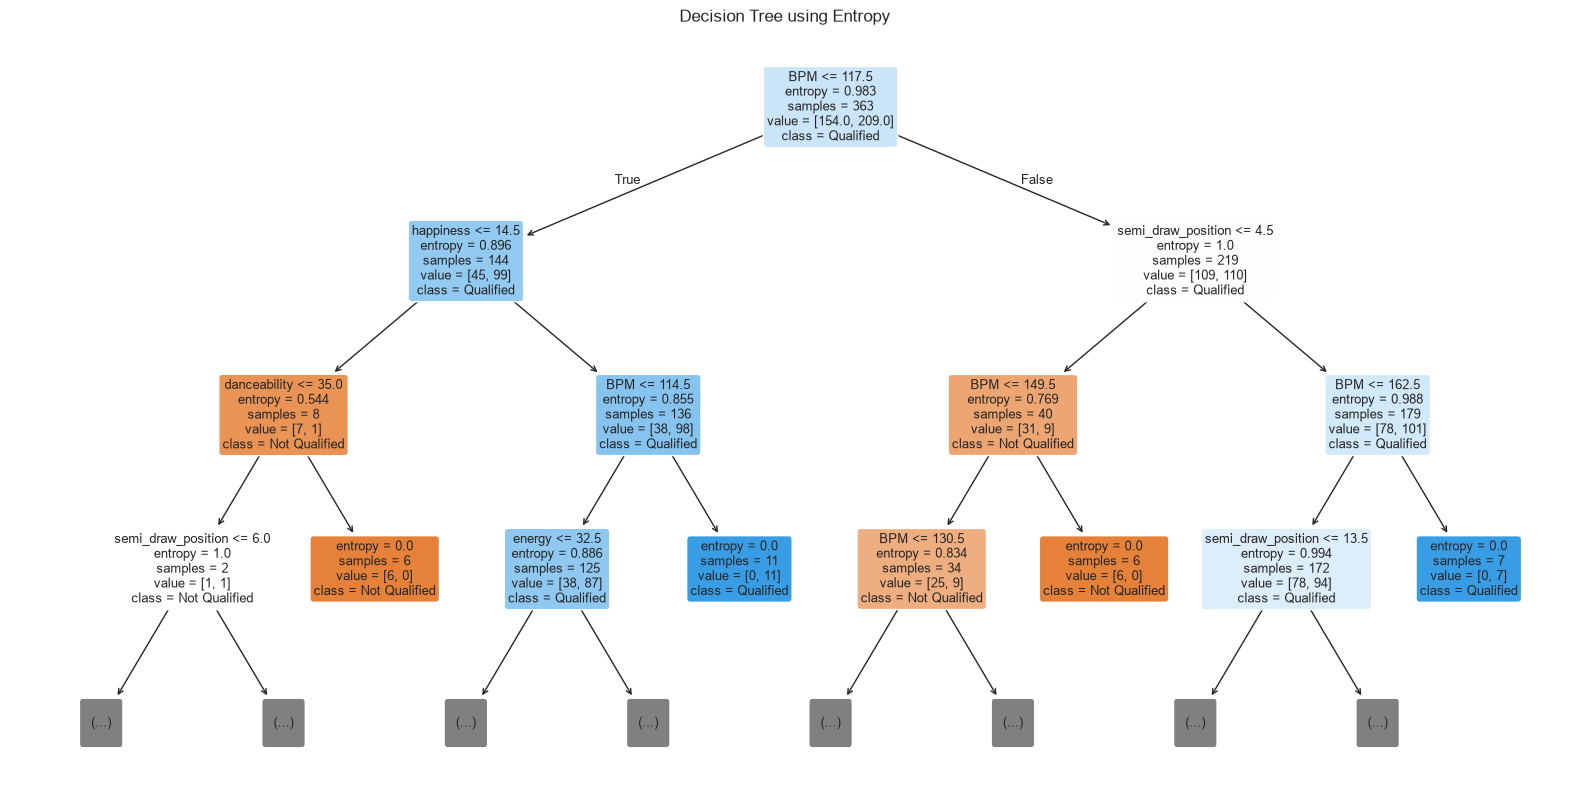

In [13]:
plt.figure(figsize=(20, 10))
trained_tree = tree_model.named_steps['tree']

plot_tree(
    trained_tree,
    feature_names=features,
    class_names=['Not Qualified', 'Qualified'],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=9
)

plt.title('Decision Tree using Entropy')
plt.show()

## Random Forest Classification

A Random Forest is an ensemble machine learning algorithm that combines multiple Decision Trees to produce predictions.

Rather than relying on a single Decision Tree, a Random Forest trains multiple trees using different samples of the training data and random selections of features.
For classification, the predictions from the individual trees are combined to determine the final predicted class.

In this experiment, a Random Forest containing 100 decision trees will be trained to predict semi final qualification.

Entropy will be used as the splitting criterion, consistent with the previous decision tree experiment.
The Random Forest results will be compared against the accuracy of the individual Decision Tree.

In [14]:
from sklearn.ensemble import RandomForestClassifier

forest_model = Pipeline([ #random forest
    ('imputer', SimpleImputer(strategy='median')),
    ('forest', RandomForestClassifier(
        n_estimators=100,
        criterion='entropy',
        random_state=42
    ))
])

forest_model.fit(Xtrain, ytrain) #fit model with eurovision data
forest_predictions = forest_model.predict(Xtest) #predict qualifiers from test data
forest_accuracy = accuracy_score(ytest, forest_predictions)
print("Random Forest accuracy is", forest_accuracy)

Random Forest accuracy is 0.5901639344262295


           Model  Accuracy
0  Decision Tree  0.565574
1  Random Forest  0.590164


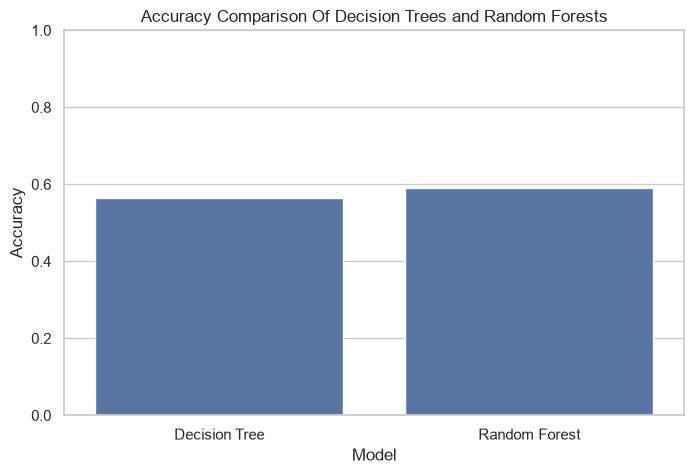

In [15]:
tree_accuracy = accuracy_score(
    ytest, tree_predictions
)
forest_accuracy = accuracy_score(
    ytest, forest_predictions
)

comparison = pd.DataFrame({ #compare the decision tree to the rndom forests
    'Model': ['Decision Tree', 'Random Forest'],
    'Accuracy': [tree_accuracy, forest_accuracy]
})

print(comparison)
plt.figure(figsize=(8, 5))

sns.barplot(
    data=comparison,
    x='Model',
    y='Accuracy'
)

plt.title('Accuracy Comparison Of Decision Trees and Random Forests')
plt.ylabel('Accuracy')
plt.xlabel('Model')
plt.ylim(0, 1)
plt.show()


In [16]:
from sklearn.dummy import DummyClassifier

baseline_model = DummyClassifier(
    strategy='most_frequent'
)

baseline_model.fit(Xtrain, ytrain)
baseline_predictions = baseline_model.predict(Xtest)

baseline_accuracy = accuracy_score(
    ytest, baseline_predictions
)

print("Baseline Accuracy:", baseline_accuracy)
print("Decision Tree Accuracy:", tree_accuracy)
print("Random Forest Accuracy:", forest_accuracy)

Baseline Accuracy: 0.5737704918032787
Decision Tree Accuracy: 0.5655737704918032
Random Forest Accuracy: 0.5901639344262295


## Random Forest Evaluation With Confusion Matrices

A confusion matrix is used to evaluate the performance of a classification model.

It compares the actual qualification results against the predictions generated by the Random Forest.
The matrix identifies four outcomes:
- True positive, which is a song correctly predicted to qualify.
- True negative, a song correctly predicted not to qualify.
- False positive, which is a song incorrectly predicted to qualify.
- False negative, a song incorrectly predicted not to qualify.

This allows the Random Forest's performance to be investigated in more detail than accuracy alone.

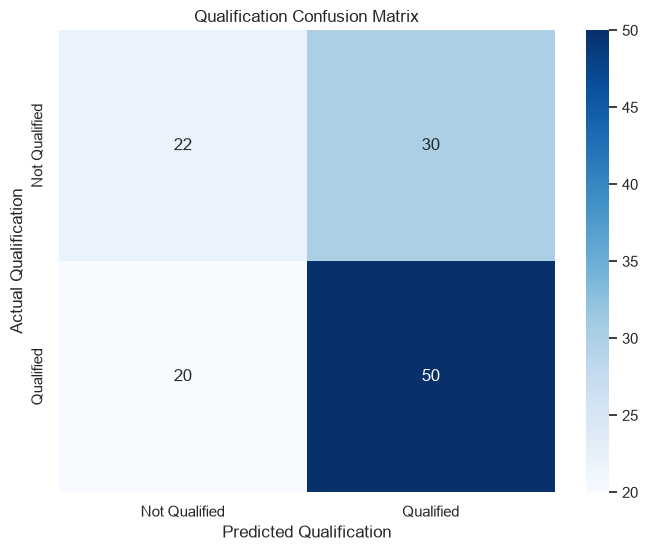

In [17]:
from sklearn.metrics import confusion_matrix

matrix = confusion_matrix(
    ytest,
    forest_predictions,
    labels=[0, 1]
)
plt.figure(figsize=(8, 6)) #show

sns.heatmap(
    matrix,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Not Qualified', 'Qualified'],
    yticklabels=['Not Qualified', 'Qualified']
)

plt.title('Qualification Confusion Matrix')
plt.xlabel('Predicted Qualification')
plt.ylabel('Actual Qualification')
plt.show()

In [18]:
tree_train_accuracy = tree_model.score(Xtrain, ytrain) # Decision Tree
tree_test_accuracy = tree_model.score(Xtest, ytest)
forest_train_accuracy = forest_model.score(Xtrain, ytrain) # Random Forest
forest_test_accuracy = forest_model.score(Xtest, ytest)

print("Decision Tree")
print("Training Accuracy:", tree_train_accuracy)
print("Testing Accuracy:", tree_test_accuracy)
print("\nRandom Forest")
print("Training Accuracy:", forest_train_accuracy)
print("Testing Accuracy:", forest_test_accuracy)

Decision Tree
Training Accuracy: 0.9586776859504132
Testing Accuracy: 0.5655737704918032

Random Forest
Training Accuracy: 0.9586776859504132
Testing Accuracy: 0.5901639344262295


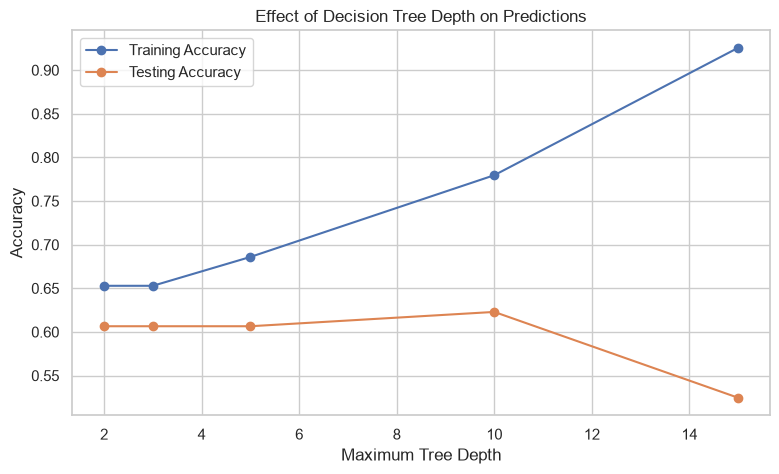

In [19]:
depths = [2, 3, 5, 10, 15]
training_scores = []
testing_scores = []
for depth in depths:
    depth_model = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('tree', DecisionTreeClassifier(
            criterion='entropy',
            max_depth=depth,
            random_state=42
        ))
    ])
    depth_model.fit(Xtrain, ytrain)
    training_scores.append(
        depth_model.score(Xtrain, ytrain)
    )
    testing_scores.append(
        depth_model.score(Xtest, ytest)
    )
plt.figure(figsize=(9, 5))

plt.plot(
    depths, training_scores,
    marker='o', label='Training Accuracy'
)
plt.plot(
    depths, testing_scores,
    marker='o', label='Testing Accuracy'
)

plt.title('Effect of Decision Tree Depth on Predictions')
plt.xlabel('Maximum Tree Depth')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()


In [20]:
pruned_forest = Pipeline([ #random forest with prepruning o compare the accuracy of an unpruned forest
    ('imputer', SimpleImputer(strategy='median')),
    ('forest', RandomForestClassifier(
        n_estimators=100,
        criterion='entropy',
        max_depth=5,
        min_samples_leaf=5,
        random_state=42
    ))
])

pruned_forest.fit(Xtrain, ytrain)
pruned_train = pruned_forest.score(Xtrain, ytrain)
pruned_test = pruned_forest.score(Xtest, ytest)

print("Original Random Forest")
print("Training:", forest_train_accuracy)
print("Testing:", forest_test_accuracy)

print("\nPruned Random Forest")
print("Training:", pruned_train)
print("Testing:", pruned_test)

Original Random Forest
Training: 0.9586776859504132
Testing: 0.5901639344262295

Pruned Random Forest
Training: 0.7465564738292011
Testing: 0.6147540983606558


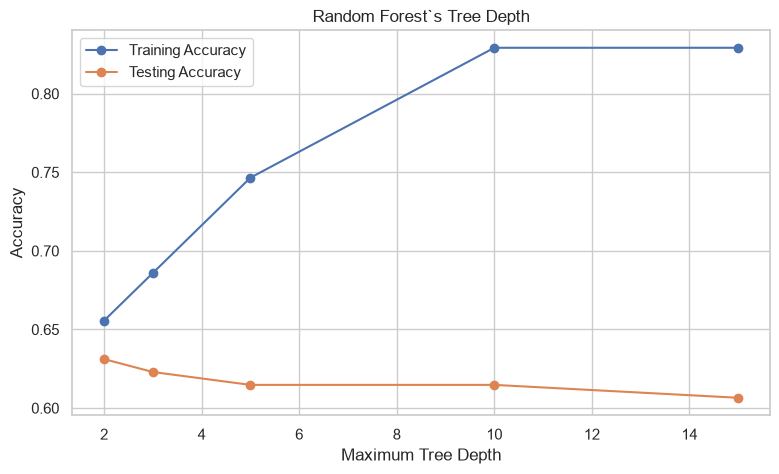

In [21]:
depths = [2, 3, 5, 10, 15]
forest_training = []
forest_testing = []
for depth in depths:
    model = Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('forest', RandomForestClassifier(
            n_estimators=100,
            criterion='entropy',
            max_depth=depth,
            min_samples_leaf=5,
            random_state=42
        ))
    ])
    model.fit(Xtrain, ytrain)
    forest_training.append(
        model.score(Xtrain, ytrain)
    )
    forest_testing.append(
        model.score(Xtest, ytest)
    )
plt.figure(figsize=(9, 5))
plt.plot(depths, forest_training, marker='o', label='Training Accuracy')
plt.plot(depths, forest_testing, marker='o', label='Testing Accuracy')

plt.title('Random Forest`s Tree Depth')
plt.xlabel('Maximum Tree Depth')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)
plt.show()

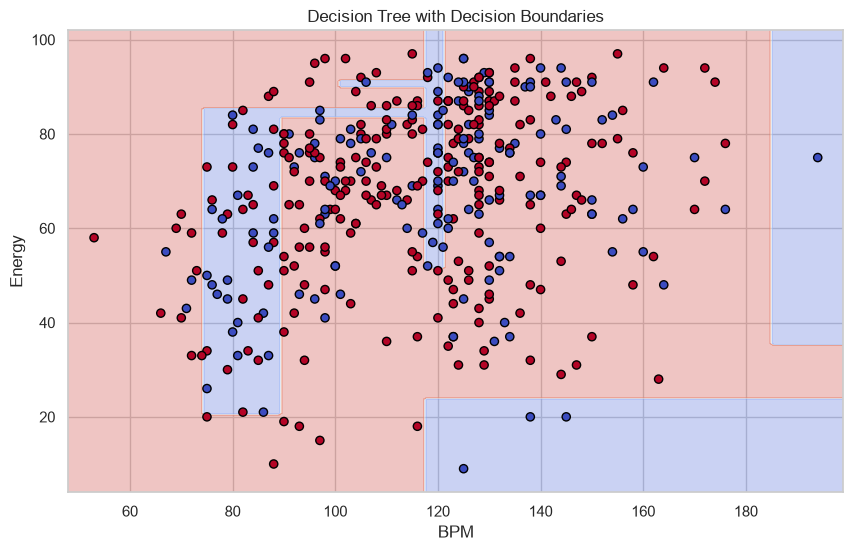

In [22]:
from sklearn.tree import DecisionTreeClassifier

X_visual = X[['BPM', 'energy']].dropna() #features for decision boundary visualisation
y_visual = y.loc[X_visual.index]

visual_model = DecisionTreeClassifier( #entroy trains tree
    criterion='entropy',
    max_depth=5,
    random_state=42
)

visual_model.fit(X_visual, y_visual)

bpm_min = X_visual['BPM'].min() - 5 #grid
bpm_max = X_visual['BPM'].max() + 5
energy_min = X_visual['energy'].min() - 5
energy_max = X_visual['energy'].max() + 5

xx, yy = np.meshgrid(
    np.linspace(bpm_min, bpm_max, 200),
    np.linspace(energy_min, energy_max, 200)
)
grid = pd.DataFrame({ #qual prediction across grid
    'BPM': xx.ravel(),
    'energy': yy.ravel()
})

predictions = visual_model.predict(grid)
predictions = predictions.reshape(xx.shape)

plt.figure(figsize=(10, 6)) #decision regions
plt.contourf(
    xx, yy, predictions,
    alpha=0.3,
    cmap='coolwarm'
)
plt.scatter(
    X_visual['BPM'],
    X_visual['energy'],
    c=y_visual,
    cmap='coolwarm',
    edgecolor='black',
    s=35
)

plt.title('Decision Tree with Decision Boundaries')
plt.xlabel('BPM')
plt.ylabel('Energy')
plt.show()

## Random Forest Feature Importance

A Random Forest can estimate how much each input feature contributes to its decisions. Here, I use the pre-pruned Random Forest trained above to compare semi-final draw position, energy, danceability, happiness and BPM.

Scikit-learn's feature_importances_ measures the average reduction in node impurity associated with each feature across the trees. The importance values sum to 1. This is not the same calculation as the permutation-based feature importance described in Chapter 8a, although both investigate which variables matter to a model.

These values explain how this model uses the features; they do not prove that a feature causes Eurovision qualification. Results should also be interpreted cautiously because the model has limited testing accuracy.

Eurovision Random Forest Feature Importance:
           Feature  Importance
               BPM    0.233771
semi_draw_position    0.212442
         happiness    0.188088
            energy    0.183025
      danceability    0.182675


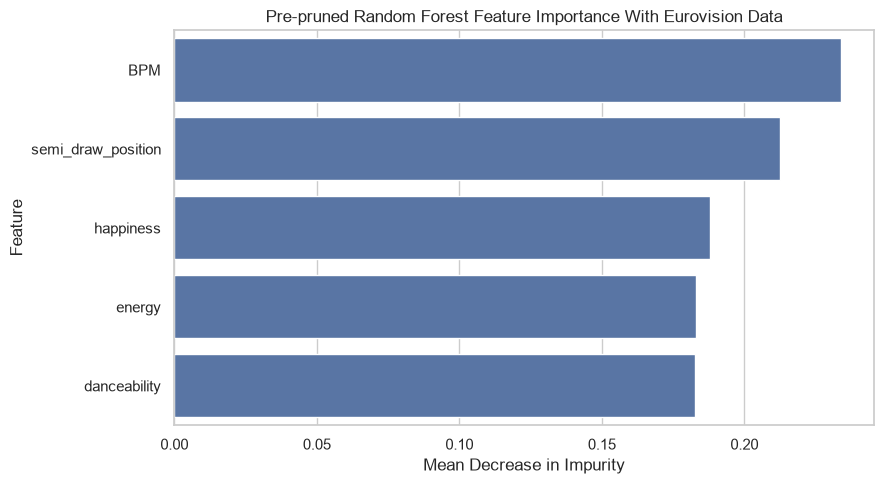

In [23]:
importances = pruned_forest.named_steps['forest'].feature_importances_ #feature importance with prepruned

importance_df = pd.DataFrame({
    'Feature': features,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

print('Eurovision Random Forest Feature Importance:')
print(importance_df.to_string(index=False))

plt.figure(figsize=(9, 5))
sns.barplot(data=importance_df, x='Importance', y='Feature')
plt.title('Pre-pruned Random Forest Feature Importance With Eurovision Data')
plt.xlabel('Mean Decrease in Impurity')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

## Results

This notebook investigated whether Decision Trees and Random Forests could predict Eurovision Song Contest semi final qualification from five characteristics: semi-final draw position, energy, danceability, happiness, and BPM. Of the 565 entries in the original dataset, 485 had a known qualification result and were used for the classification experiments. The audio features contained missing values, so I used median imputation within the model pipelines.

## Entropy and Information Gain

The qualification labels consisted of 279 qualifiers and 206 non-qualifiers, giving an overall entropy of 0.9836. This is close to the maximum entropy of 1 for a two class problem and indicates that the outcomes were relatively mixed. A demonstration split at the median BPM of 120 produced an Information Gain of only 0.0002. Therefore, this particular BPM split did very little to separate qualifying songs from non-qualifying songs. It does not mean that BPM is necessarily unhelpful at every possible threshold.

## Comparing the Models

The dataset was divided into 363 training entries and 122 testing entries. The Decision Tree using Entropy achieved 56.56% testing accuracy, while the original Random Forest of 100 trees achieved 59.02%. This was a small improvement, illustrating how combining several decision trees through an ensemble can change classification performance. However, a simple baseline that predicted the most common class achieved 57.38%, so the original Random Forest was only slightly better than this baseline. The confusion matrix was also used to inspect correct and incorrect predictions for the two qualification classes, rather than relying on accuracy alone.

## Overfitting and Pre-pruning

The original decision tree and random forest both achieved 95.87% training accuracy, compared with testing accuracies of 56.56% and 59.02%, respectively. These large differences suggest overfitting, meaning the models classified the training entries well but struggled to generalise to unseen entries.

To investigate this, I tested different maximum depths for the decision tree and random forest. I also applied pre-pruning to the Random Forest by setting max_depth=5 and min_samples_leaf=5. The pre-pruned forest achieved 74.66% training accuracy and 61.48% testing accuracy. Its training and testing accuracy gap fell from approximately 36.85 percentage points to 13.18 percentage points. This suggests that limiting tree complexity reduced overfitting in this experiment. The improvement in testing accuracy was modest, however, and does not guarantee better performance in future Eurovision contests.

## Decision Boundaries and Feature Importance

A separate decision tree using only BPM and energy was used to visualise decision boundaries. Its rectangular regions show how a tree divides the feature space into areas assigned different qualification predictions, similar to the two-feature examples in the lecture material. This visualisation is illustrative and is not the same as evaluating the main five-feature Random Forest.

The feature importance analysis of the pre-pruned Random Forest ranked BPM (23.38%) first, followed by semi-final draw position (21.24%), happiness (18.81%), energy (18.30%) and danceability (18.27%). The values are fairly close, suggesting that no single measured characteristic completely dominates the model's splitting decisions. These are measures of the model's use of features, not evidence that changing a feature would cause a song to qualify.

## Overall Conclusion and Limitations

The experiments demonstrate the use of entropy, information gain, decision trees, random forests, ensemble learning, and pre-pruning on a real Eurovision dataset. Pre-pruning produced a less overfitted model and a slightly higher test accuracy, but even the best observed accuracy of 61.48% was only moderately above the baseline of 57.38%. The selected musical characteristics and running order therefore provide limited predictive information in these experiments.

One limitation is that the models do not include factors such as live vocal performance, staging, or audience response, which may influence qualification. Missing audio data also required imputation. In addition, several depth settings were explored using the same test split; ideally, a separate development set would be used to choose model settings before a final evaluation on untouched test data, as described in the Random Forest lecture. The results should therefore be considered exploratory rather than a reliable way to forecast future Eurovision qualifications.

## References

1. **GeeksforGeeks, Random Forest Classifier using Scikit-learn**  
   https://www.geeksforgeeks.org/random-forest-classifier-using-scikit-learn/

2. **GeeksforGeeks, Decision Tree Introduction with Example**  
   https://www.geeksforgeeks.org/machine-learning/decision-tree-introduction-example/

3. **GeeksforGeeks, Random Forest Algorithm in Machine Learning**  
   https://www.geeksforgeeks.org/machine-learning/random-forest-algorithm-in-machine-learning/

4. **VanderPlas, J., Python Data Science Handbook**  
   https://github.com/jakevdp/PythonDataScienceHandbook/blob/master/notebooks/05.08-Random-Forests.ipynb

5. **Scikit-learn, RandomForestClassifier Documentation**  
   https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html

6. **Scikit-learn, Feature Importances with a Forest of Trees**  
   https://scikit-learn.org/stable/auto_examples/ensemble/plot_forest_importances.html

7. **Scikit-learn, Pipeline Documentation**  
   https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html

8. **Scikit-learn, train_test_split Documentation**  
   https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html

9. **Scikit-learn, DummyClassifieer Documentation**  
   https://scikit-learn.org/stable/modules/generated/sklearn.dummy.DummyClassifier.html

10. **Scikit-learn, Decision Trees User Guide**  
    https://scikit-learn.org/stable/modules/tree.html
